# ****EVALUATION****

Notebook ini mengukur seluruh model pada data uji, yaitu data yang tidak pernah dipakai untuk membangun atau memilih model apa pun. Hasil pada notebook ini adalah ukuran kinerja yang paling jujur.

<p align="center">
    <img src="../xLain_Lain/img/e_0.png" alt="Evaluation" witdh="100" height="500">
</p>

---

### ****DAFTAR ISI****

0. Persiapan dan Protokol yang Dikunci Sebelum Melihat Hasil
1. Pelatihan Ulang Model dan Peramalan Data Uji
2. Hasil pada Data Uji
3. Rincian Galat: Hari dalam Minggu dan Hari Harga Berubah
4. Uji Statistik Selisih Antar Model
5. Ringkasan dan Langkah Berikutnya

### ****0. Persiapan dan Protokol yang Dikunci Sebelum Melihat Hasil****

#### ****0.1 Mengapa langkah ini penting?****

Data uji adalah satu-satunya ukuran yang jujur tentang kinerja pada data yang belum pernah dilihat. Begitu data uji dipakai untuk menyetel sesuatu, ia berhenti menjadi ukuran yang jujur. Karena itu protokol dan ekspektasi dicatat sebelum hasil dilihat, dan tidak diubah sesudahnya.

#### ****0.2 Protokol yang dikunci****

1. Seluruh model dilatih ulang pada gabungan data latih dan data validasi (1.482 hari), dengan konfigurasi yang sudah terkunci dari Notebook 4 dan 5.
2. Algoritma Genetika dijalankan ulang untuk K = 7, 10, 15, dan 20 dengan parameter dan 30 seed yang sama seperti pada Notebook 5. Seed terbaik dipilih menurut MAPE pada data pelatihan akhir, bukan menurut data uji.
3. Peramalan bersifat satu langkah: harga setiap hari uji diramalkan dari harga aktual pencatatan sebelumnya.
4. Ukuran yang dilaporkan adalah MAPE, RMSE, dan MAE, dirinci menurut hari dalam minggu dan menurut hari harga berubah atau tidak, serta diuji dengan uji Diebold-Mariano untuk empat pembandingan terhadap GA-FTS pada K terpilih (K = 20) dengan koreksi Bonferroni.
5. Setelah hasil dilihat, tidak ada konfigurasi yang diubah dan tidak ada analisis tambahan yang dipilih berdasarkan hasil.

#### ****0.3 Ekspektasi sebelum melihat hasil****

Berdasarkan hasil validasi, ekspektasi kami adalah:
1. GA-FTS lebih baik daripada Fuzzy Time Series interval sama panjang pada K yang sama.
2. GA-FTS tidak berbeda nyata dari pembagian kuantil pada K = 20.
3. GA-FTS lebih buruk daripada naive dan ARIMA.
4. Hari Senin menghasilkan galat terbesar pada seluruh model.

Ekspektasi ini dapat terbukti maupun tidak. Apa pun hasilnya, dilaporkan apa adanya.

#### ****0.4 Membuka data uji****

Sel berikut membuka data uji untuk pertama kali, memuat konfigurasi terkunci, memeriksa apakah nilai uji berada dalam rentang harga data pelatihan, dan menyiapkan harga pencatatan sebelumnya sebagai acuan tiap hari uji.

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import t as dist_t

import config
from src.metrics import ringkas_metrik
from src.fts import interval_sama_panjang, FuzzyTimeSeriesChen
from src.ga import jalankan_ga, batas_kuantil

rupiah = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

pembagian = pd.read_csv(config.DIR_CLEAN / "pembagian_data.csv", parse_dates=["tanggal"])
latih = pembagian[pembagian["subset"] == "latih"].set_index("tanggal")["harga"]
validasi = pembagian[pembagian["subset"] == "validasi"].set_index("tanggal")["harga"]
uji = pembagian[pembagian["subset"] == "uji"].set_index("tanggal")["harga"]

latih_akhir = pd.concat([latih, validasi])
semua = pd.concat([latih_akhir, uji])
acuan_uji = semua.shift(1).loc[uji.index]

with open(config.DIR_MODEL / "konfigurasi_baseline.json", encoding="utf-8") as f:
    konf_base = json.load(f)
with open(config.DIR_MODEL / "konfigurasi_ga.json", encoding="utf-8") as f:
    konf_ga = json.load(f)

luar = int(((uji < latih_akhir.min()) | (uji > latih_akhir.max())).sum())

print("=" * 62)
print("Data uji dibuka")
print("=" * 62)
print(f"Data pelatihan akhir : {len(latih_akhir)} hari ({latih_akhir.index.min().date()} sampai {latih_akhir.index.max().date()})")
print(f"Data uji : {len(uji)} hari ({uji.index.min().date()} sampai {uji.index.max().date()})")
print(f"Rentang harga pelatihan akhir : Rp {latih_akhir.min():,.0f} sampai Rp {latih_akhir.max():,.0f}")
print(f"Nilai uji di luar rentang tersebut : {luar} dari {len(uji)}")
print(f"Acuan uji pertama sama dengan harga pelatihan terakhir : {acuan_uji.iloc[0] == latih_akhir.iloc[-1]}")
print()
print("Konfigurasi terkunci dari Notebook 4 dan 5:")
print(f"Model dasar : {konf_base}")
print(f"GA : K = {konf_ga['daftar_K']}, {konf_ga['jumlah_seed']} seed, K terpilih = {konf_ga['K_terpilih_menurut_validasi']}")

Data uji dibuka
Data pelatihan akhir : 1482 hari (2020-01-02 sampai 2025-11-06)
Data uji : 263 hari (2025-11-07 sampai 2026-11-10)
Rentang harga pelatihan akhir : Rp 13,650 sampai Rp 110,800
Nilai uji di luar rentang tersebut : 0 dari 263
Acuan uji pertama sama dengan harga pelatihan terakhir : True

Konfigurasi terkunci dari Notebook 4 dan 5:
Model dasar : {'moving_average_k': 2, 'regresi_linear_lag': 7, 'perceptron_lag': 5, 'fts_sama_panjang_K_rancangan': 15, 'fts_sama_panjang_K_rujukan': 150, 'arima_orde': [3, 1, 2]}
GA : K = [7, 10, 15, 20], 30 seed, K terpilih = 20


>INTERPRETASI (Pembukaan data uji)
>
>Data uji berisi 263 hari kerja (7 November 2025 sampai 10 November 2026), dan seluruh model dilatih ulang pada 1.482 hari (2 Januari 2020 sampai 6 November 2025). Seluruh nilai uji berada dalam rentang harga data pelatihan akhir (Rp 13.650 sampai Rp 110.800), sehingga tidak ada harga uji yang jatuh di luar semesta Fuzzy Time Series. Acuan hari uji pertama sama dengan harga pelatihan terakhir, dan konfigurasi yang dipakai sama dengan yang dikunci pada Notebook 4 dan 5.

### ****1. Pelatihan Ulang Model dan Peramalan Data Uji****

#### ****1.1 Mengapa langkah ini penting?****

Sistem nyata akan memakai seluruh data yang tersedia, bukan hanya data latih. Karena itu setiap model dilatih ulang pada gabungan data latih dan validasi, dengan konfigurasi (jendela, lag, orde, dan jumlah interval) yang dikunci dari notebook sebelumnya. Dengan begitu data uji tetap benar-benar baru bagi semua model.

#### ****1.2 Yang dilakukan****

Dua sel berikut:
1. Melatih ulang model dasar dan meramalkan data uji: naive, moving average, regresi linear, perceptron berlapis (lima seed), ARIMA, serta Fuzzy Time Series interval sama panjang dan berfrekuensi sama untuk K = 7, 10, 15, dan 20 (ditambah K = 150 sebagai rujukan). Pada ARIMA, parameter dicocokkan ulang pada data pelatihan akhir dan peramalan dilakukan tanpa pencocokan ulang.
2. Menjalankan ulang Algoritma Genetika untuk K = 7, 10, 15, dan 20 dengan 30 seed, memilih seed terbaik menurut MAPE pada data pelatihan akhir, dan menyimpan model hasilnya di folder Model agar dapat dipakai pada penerapan web. Sel ini membutuhkan beberapa menit.

In [4]:
import warnings
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA

DAFTAR_K = konf_ga["daftar_K"]
K_RUJUKAN = konf_base["fts_sama_panjang_K_rujukan"]
K_TERPILIH = konf_ga["K_terpilih_menurut_validasi"]

prediksi_uji, metrik_uji = {}, {}


def catat(nama, pred):
    prediksi_uji[nama] = pd.Series(np.asarray(pred, dtype=float), index=uji.index)
    metrik_uji[nama] = ringkas_metrik(uji, prediksi_uji[nama])


def buat_fitur(seri, panjang_lag):
    nilai = seri.values.astype(float)
    X = np.array([nilai[i - panjang_lag:i] for i in range(panjang_lag, len(nilai))])
    return X, nilai[panjang_lag:], seri.index[panjang_lag:]


# Naive dan moving average
catat("Naive", acuan_uji.values)
k_ma = konf_base["moving_average_k"]
catat(f"Moving average (k={k_ma})", semua.rolling(k_ma).mean().shift(1).loc[uji.index].values)

# Regresi linear
L = konf_base["regresi_linear_lag"]
X_lat, y_lat, _ = buat_fitur(latih_akhir, L)
model_lr = LinearRegression().fit(X_lat, y_lat)
X_all, _, idx_all = buat_fitur(semua, L)
catat(f"Regresi linear (lag={L})", model_lr.predict(X_all[idx_all.isin(uji.index)]))

# Perceptron berlapis, lima seed
L_mlp = konf_base["perceptron_lag"]
mu, sigma = latih_akhir.mean(), latih_akhir.std()
X_lat, y_lat, _ = buat_fitur(latih_akhir, L_mlp)
X_all, _, idx_all = buat_fitur(semua, L_mlp)
X_uji = X_all[idx_all.isin(uji.index)]
metrik_seed, pred_seed = [], []
for i in range(5):
    mlp = MLPRegressor(hidden_layer_sizes=(16,), max_iter=3000, random_state=config.SEED + i)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        mlp.fit((X_lat - mu) / sigma, (y_lat - mu) / sigma)
    p = mlp.predict((X_uji - mu) / sigma) * sigma + mu
    pred_seed.append(p)
    metrik_seed.append(ringkas_metrik(uji, p))
nama_mlp = f"Perceptron berlapis (lag={L_mlp}, 16 neuron)"
prediksi_uji[nama_mlp] = pd.Series(np.mean(pred_seed, axis=0), index=uji.index)
metrik_uji[nama_mlp] = pd.DataFrame(metrik_seed).mean().to_dict()

# ARIMA: parameter dicocokkan ulang pada data pelatihan akhir, ramalan satu langkah tanpa pencocokan ulang
orde = tuple(konf_base["arima_orde"])
nama_arima = f"ARIMA{orde}"
hasil_arima = ARIMA(latih_akhir.values.astype(float), order=orde, trend="n" if orde[1] == 1 else "c").fit()
terapan = hasil_arima.apply(semua.values.astype(float), refit=False)
catat(nama_arima, pd.Series(np.asarray(terapan.fittedvalues), index=semua.index).loc[uji.index].values)

# Fuzzy Time Series interval sama panjang dan kuantil
for K in DAFTAR_K + [K_RUJUKAN]:
    b = interval_sama_panjang(latih_akhir.values, K)
    catat(f"FTS interval sama panjang (K={K})", FuzzyTimeSeriesChen(b).fit(latih_akhir.values).ramal(acuan_uji.values))
for K in DAFTAR_K:
    b = batas_kuantil(latih_akhir.values, K)
    catat(f"FTS kuantil (K={K})", FuzzyTimeSeriesChen(b).fit(latih_akhir.values).ramal(acuan_uji.values))

print("=" * 62)
print("Model dasar selesai dilatih ulang dan memprediksi data uji")
print("=" * 62)
for nama in metrik_uji:
    print(f"  {nama}")
print(f"Jumlah model: {len(metrik_uji)}")

Model dasar selesai dilatih ulang dan memprediksi data uji
  Naive
  Moving average (k=2)
  Regresi linear (lag=7)
  Perceptron berlapis (lag=5, 16 neuron)
  ARIMA(3, 1, 2)
  FTS interval sama panjang (K=7)
  FTS interval sama panjang (K=10)
  FTS interval sama panjang (K=15)
  FTS interval sama panjang (K=20)
  FTS interval sama panjang (K=150)
  FTS kuantil (K=7)
  FTS kuantil (K=10)
  FTS kuantil (K=15)
  FTS kuantil (K=20)
Jumlah model: 14


>INTERPRETASI (Pelatihan ulang)
>
>Empat belas model dasar berhasil dilatih ulang dan meramalkan data uji. Algoritma Genetika dijalankan 120 kali (30 seed untuk tiap K dari empat nilai K) dalam sekitar 112 detik. Seed terbaik dipilih menurut MAPE pada data pelatihan akhir: seed 69 pada K = 7 (MAPE pelatihan akhir 9,42%), seed 56 pada K = 10 (6,98%), seed 63 pada K = 15 (5,77%), dan seed 69 pada K = 20 (5,41%). Pemilihan ini dilakukan tanpa melihat data uji, sehingga hasil uji tidak dipengaruhi pemilihan seed. Seed terpilih berbeda dari Notebook 5 karena data pelatihan kini lebih panjang. Model tersimpan di berkas model_ga_akhir.json.

In [5]:
import time

PARAM_GA = konf_ga["parameter"]
JUMLAH_SEED, SEED_AWAL = konf_ga["jumlah_seed"], konf_ga["seed_awal"]

baris_seed, ga_terbaik = [], {}
mulai = time.time()
for K in DAFTAR_K:
    hasil_k = []
    for i in range(JUMLAH_SEED):
        seed = SEED_AWAL + i
        ga = jalankan_ga(latih_akhir.values, K, seed=seed, **PARAM_GA)
        pred = FuzzyTimeSeriesChen(ga["batas"]).fit(latih_akhir.values).ramal(acuan_uji.values)
        hasil_k.append({"seed": seed, "mape_latih_akhir": ga["mape_latih"], "batas": ga["batas"], "pred": pred})
        baris_seed.append({"K": K, "seed": seed, "mape_latih_akhir": ga["mape_latih"],
                           "mape_uji": ringkas_metrik(uji, pred)["MAPE_%"]})
    terbaik = min(hasil_k, key=lambda h: h["mape_latih_akhir"])
    ga_terbaik[K] = terbaik
    catat(f"GA-FTS (K={K})", terbaik["pred"])
    print(f"K = {K:<2} selesai (waktu berjalan {time.time() - mulai:.0f} detik)")

seed_df = pd.DataFrame(baris_seed)
seed_df.to_csv(config.DIR_MODEL / "hasil_ga_uji_per_seed.csv", index=False)
with open(config.DIR_MODEL / "model_ga_akhir.json", "w", encoding="utf-8") as f:
    json.dump({
        "dilatih_pada": [str(latih_akhir.index.min().date()), str(latih_akhir.index.max().date())],
        "parameter": PARAM_GA,
        "K_terpilih": K_TERPILIH,
        "model": {str(K): {"seed": int(h["seed"]), "mape_latih_akhir": float(h["mape_latih_akhir"]),
                           "batas": [float(x) for x in h["batas"]]} for K, h in ga_terbaik.items()},
    }, f, indent=2, ensure_ascii=False)

print()
print("Seed dipilih menurut MAPE pada data pelatihan akhir (bukan menurut data uji):")
for K, h in ga_terbaik.items():
    print(f"  K = {K:<2} seed {h['seed']}: MAPE pelatihan akhir {h['mape_latih_akhir']:.2f}%")
print("Tersimpan: model_ga_akhir.json dan hasil_ga_uji_per_seed.csv di folder Model")

K = 7  selesai (waktu berjalan 25 detik)
K = 10 selesai (waktu berjalan 53 detik)
K = 15 selesai (waktu berjalan 82 detik)
K = 20 selesai (waktu berjalan 112 detik)

Seed dipilih menurut MAPE pada data pelatihan akhir (bukan menurut data uji):
  K = 7  seed 69: MAPE pelatihan akhir 9.42%
  K = 10 seed 56: MAPE pelatihan akhir 6.98%
  K = 15 seed 63: MAPE pelatihan akhir 5.77%
  K = 20 seed 69: MAPE pelatihan akhir 5.41%
Tersimpan: model_ga_akhir.json dan hasil_ga_uji_per_seed.csv di folder Model


### ****2. Hasil pada Data Uji****

#### ****2.1 Mengapa langkah ini penting?****

Inilah jawaban atas pertanyaan proyek pada data yang tidak pernah dipakai untuk membangun atau memilih model: apakah Fuzzy Time Series yang batas intervalnya dioptimasi Algoritma Genetika benar-benar lebih baik, dan di mana posisinya dibanding model lain.

#### ****2.2 Yang dilakukan****

Sel berikut:
1. Menampilkan MAPE, RMSE, dan MAE seluruh model, diurutkan menurut MAPE, dan menyimpannya ke folder Model.
2. Menampilkan stabilitas Algoritma Genetika pada data uji untuk 30 seed per K. Angka ini hanya untuk pelaporan sebaran, bukan untuk memilih seed.
3. Menggambar grafik batang MAPE seluruh model dan grafik ramalan satu langkah selama periode uji.

hasil pada data uji (urut MAPE)
                                        MAPE_%      RMSE      MAE  MAPE_terhadap_naive_(kali)
Regresi linear (lag=7)                    3.67   4019.05  2250.89                        0.95
ARIMA(3, 1, 2)                            3.71   4037.17  2271.98                        0.96
Naive                                     3.86   4071.29  2305.32                        1.00
Perceptron berlapis (lag=5, 16 neuron)    4.58   4504.80  2757.71                        1.19
FTS interval sama panjang (K=150)         4.59   4397.43  2733.11                        1.19
Moving average (k=2)                      5.19   4929.94  3076.90                        1.35
GA-FTS (K=20)                             5.31   4863.81  3191.96                        1.38
GA-FTS (K=15)                             5.50   4783.57  3267.76                        1.43
FTS interval sama panjang (K=20)          5.95   4756.68  3404.82                        1.54
GA-FTS (K=10)               

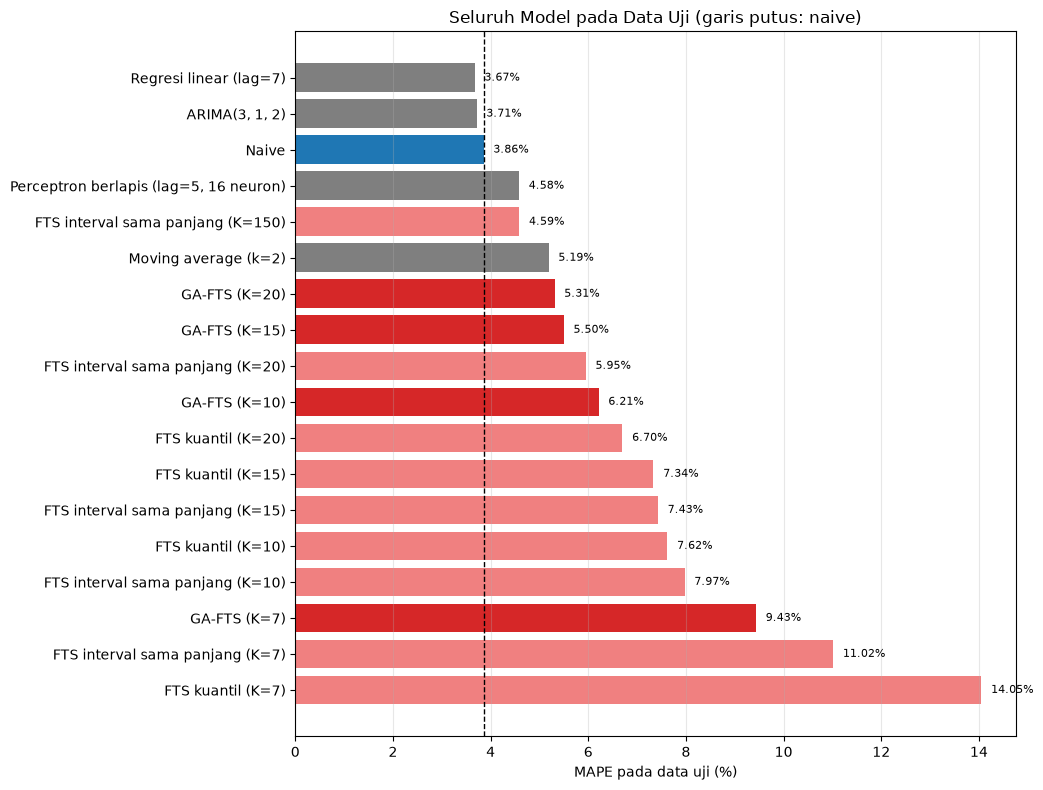

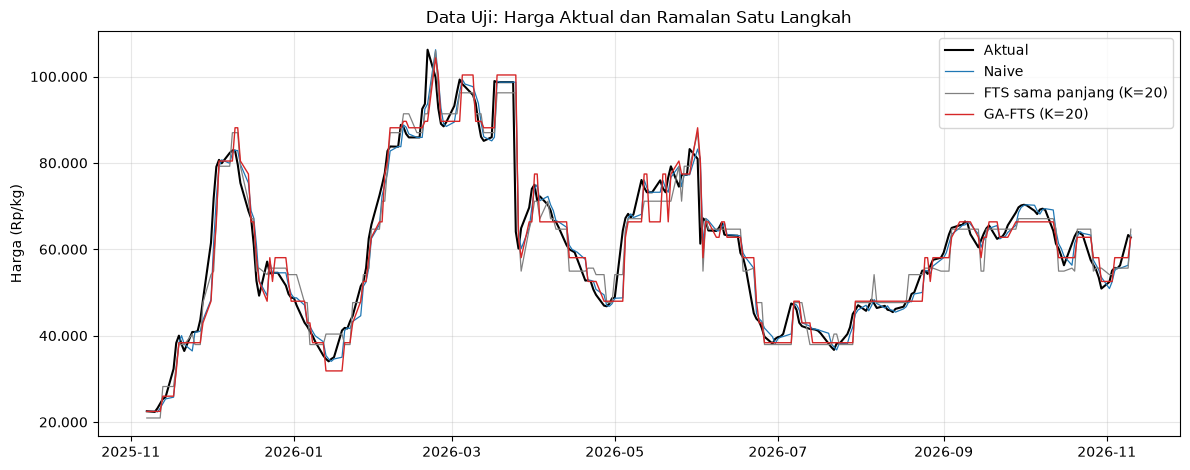

In [6]:
hasil_uji = pd.DataFrame(metrik_uji).T
hasil_uji["MAPE_terhadap_naive_(kali)"] = hasil_uji["MAPE_%"] / hasil_uji.loc["Naive", "MAPE_%"]
hasil_uji = hasil_uji.sort_values("MAPE_%")
hasil_uji.to_csv(config.DIR_MODEL / "hasil_uji_akhir.csv")

print("=" * 62)
print("hasil pada data uji (urut MAPE)")
print("=" * 62)
print(hasil_uji.round(2).to_string())

stabilitas = seed_df.groupby("K").agg(
    mape_latih_akhir_rata2=("mape_latih_akhir", "mean"),
    mape_uji_rata2=("mape_uji", "mean"),
    mape_uji_std=("mape_uji", "std"),
    mape_uji_min=("mape_uji", "min"),
    mape_uji_maks=("mape_uji", "max"),
)
stabilitas["mape_uji_seed_terpilih"] = [metrik_uji[f"GA-FTS (K={K})"]["MAPE_%"] for K in stabilitas.index]
stabilitas.to_csv(config.DIR_MODEL / "stabilitas_ga_uji.csv")

print()
print("=" * 62)
print(f"stabilitas algoritma genetika pada data uji ({JUMLAH_SEED} seed per K; hanya untuk pelaporan)")
print("=" * 62)
print(stabilitas.round(2).to_string())

fig, ax = plt.subplots(figsize=(10.5, 8))
urut = hasil_uji["MAPE_%"].sort_values(ascending=False)


def warna_model(n):
    if n == "Naive":
        return "tab:blue"
    if n.startswith("GA-FTS"):
        return "tab:red"
    if n.startswith("FTS"):
        return "lightcoral"
    return "tab:gray"


ax.barh(urut.index, urut.values, color=[warna_model(n) for n in urut.index])
ax.axvline(hasil_uji.loc["Naive", "MAPE_%"], color="black", linestyle="--", linewidth=1)
for i, nilai in enumerate(urut.values):
    ax.text(nilai + 0.2, i, f"{nilai:.2f}%", va="center", fontsize=8)
ax.set_xlabel("MAPE pada data uji (%)")
ax.set_title("Seluruh Model pada Data Uji (garis putus: naive)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(config.DIR_IMG / "6_mape_uji_semua_model.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(uji.index, uji.values, color="black", linewidth=1.5, label="Aktual")
ax.plot(uji.index, prediksi_uji["Naive"].values, color="tab:blue", linewidth=0.9, label="Naive")
ax.plot(uji.index, prediksi_uji[f"FTS interval sama panjang (K={K_TERPILIH})"].values, color="gray",
        linewidth=0.9, label=f"FTS sama panjang (K={K_TERPILIH})")
ax.plot(uji.index, prediksi_uji[f"GA-FTS (K={K_TERPILIH})"].values, color="tab:red",
        linewidth=1.0, label=f"GA-FTS (K={K_TERPILIH})")
ax.set_title("Data Uji: Harga Aktual dan Ramalan Satu Langkah")
ax.set_ylabel("Harga (Rp/kg)")
ax.yaxis.set_major_formatter(rupiah)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(config.DIR_IMG / "6_ramalan_uji.png", dpi=150)
plt.show()

>INTERPRETASI (Hasil pada data uji)
>
>Tiga model terbaik berselisih kurang dari 0,2 poin persen: regresi linear (lag 7) 3,67%, ARIMA(3,1,2) 3,71%, dan naive 3,86%. Regresi linear dan ARIMA masing-masing sekitar 5% dan 4% lebih kecil kesalahannya daripada naive, tetapi selisih ini tidak diuji kemaknaannya. GA-FTS pada K terpilih (K = 20) menghasilkan MAPE 5,31%, RMSE Rp 4.864, dan MAE Rp 3.192, atau 1,38 kali MAPE naive. Ini hasil terbaik di antara seluruh Fuzzy Time Series pada K sampai 20: berikutnya GA-FTS K = 15 (5,50%) dan interval sama panjang K = 20 (5,95%). Perceptron berlapis (4,58%), Fuzzy Time Series K = 150 (4,59%), dan moving average (5,19%) masih lebih baik daripada GA-FTS K = 20.
>
>Terhadap interval sama panjang pada K yang sama, GA-FTS memiliki MAPE lebih rendah pada keempat K: 9,43% dibanding 11,02% (K = 7, turun 14,4%), 6,21% dibanding 7,97% (K = 10, turun 22,1%), 5,50% dibanding 7,43% (K = 15, turun 26,0%), dan 5,31% dibanding 5,95% (K = 20, turun 10,8%). Pada validasi, perbaikan di K = 20 adalah 33,5%. Perbaikan menyusut karena interval sama panjang K = 20 jauh membaik pada data uji (9,14% menjadi 5,95%). Urutan K = 15 dan K = 20 pada interval sama panjang bahkan berbalik antara validasi (K = 15 lebih baik) dan uji (K = 20 lebih baik). Ini menunjukkan hasil pembagian sama panjang sensitif terhadap letak batas dan tidak stabil antar periode.
>
>Terhadap pembagian berfrekuensi sama, GA-FTS lebih baik pada keempat K di data uji (9,43% dibanding 14,05%, 6,21% dibanding 7,62%, 5,50% dibanding 7,34%, dan 5,31% dibanding 6,70%). Kekalahan GA-FTS dari kuantil pada K = 10 di data validasi tidak berulang pada data uji, sementara pembagian kuantil memburuk pada K = 20 (6,09% menjadi 6,70%).
>
>Ukuran lain tidak sepenuhnya searah. Berdasarkan RMSE, GA-FTS lebih buruk daripada interval sama panjang pada K = 7 (Rp 8.574 dibanding Rp 7.305) dan K = 20 (Rp 4.864 dibanding Rp 4.757), dan berdasarkan MAE lebih buruk pada K = 7 (Rp 6.206 dibanding Rp 5.867). Dugaan kami, Algoritma Genetika mengoptimasi MAPE (kesalahan relatif), yang memberi bobot lebih besar pada harga rendah, sehingga batas dirapatkan di harga rendah dan interval harga tinggi dibiarkan lebar. Contohnya, model K = 7 yang tersimpan memiliki interval teratas selebar sekitar Rp 42.700 (Rp 68.127 sampai Rp 110.800). RMSE menghukum kesalahan besar pada harga tinggi. Dugaan ini belum diuji.
>
>Sebaran hasil 30 seed pada data uji sempit: simpangan baku MAPE uji 0,30 (K = 7), 0,30 (K = 10), 0,22 (K = 15), dan 0,24 (K = 20). Seed terpilih menurut MAPE latih menghasilkan MAPE uji yang dekat dengan rata-rata seed (misalnya 5,31% dibanding 5,16% pada K = 20 dan 5,50% dibanding 5,41% pada K = 15), sehingga pemilihan seed tidak menguntungkan maupun merugikan secara berarti. Seed terbaik pada K = 20 (MAPE uji minimum 4,60%) pun masih lebih buruk daripada naive (3,86%), sehingga tidak ada seed yang menyamai naive. Simpangan baku pada K = 10 jauh lebih kecil pada data uji (0,30) daripada pada validasi (1,09), dan penyebabnya tidak diselidiki.
>
>Pada grafik batang, seluruh Fuzzy Time Series dengan K sampai 20 (batang merah) berada di sebelah kanan garis naive. Pada grafik ramalan, semua model mengikuti harga aktual dengan keterlambatan satu pencatatan, dan GA-FTS berbentuk anak tangga. Tidak ada model yang mengantisipasi penurunan tajam pada akhir Maret 2026 (dari sekitar Rp 99.000 ke sekitar Rp 64.000 dalam satu pencatatan) maupun lonjakan pada awal Juni 2026 (sekitar Rp 81.000, lalu Rp 61.300).

### ****3. Rincian Galat: Hari dalam Minggu dan Hari Harga Berubah****

#### ****3.1 Mengapa langkah ini penting?****

MAPE rata-rata dapat menyembunyikan pola. Pada Notebook 3 ditemukan bahwa hari Senin jauh lebih bergejolak daripada hari lain, dan diduga sejak 2023 hari libur diisi dengan pengulangan harga terakhir. Pengulangan seperti ini membuat sebagian hari uji mudah ditebak oleh model yang hanya mengulang harga kemarin, sehingga kinerjanya dapat tampak lebih baik dari yang sebenarnya.

#### ****3.2 Yang dilakukan****

Sel berikut menghitung MAPE lima model terpilih (naive, ARIMA, Fuzzy Time Series sama panjang, Fuzzy Time Series kuantil, dan GA-FTS pada K terpilih) menurut hari pencatatan, lalu memisahkan hari ketika harga berubah dari hari ketika harga sama dengan pencatatan sebelumnya.

In [7]:
kunci_pilihan = {
    "Naive": "Naive",
    nama_arima: nama_arima,
    f"FTS sama panjang (K={K_TERPILIH})": f"FTS interval sama panjang (K={K_TERPILIH})",
    f"FTS kuantil (K={K_TERPILIH})": f"FTS kuantil (K={K_TERPILIH})",
    f"GA-FTS (K={K_TERPILIH})": f"GA-FTS (K={K_TERPILIH})",
}
ape = {nama: (uji - prediksi_uji[kunci]).abs() / uji * 100 for nama, kunci in kunci_pilihan.items()}

nama_hari = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat"}
hari = uji.index.day_of_week
per_hari = pd.DataFrame({n: s.groupby(hari).mean() for n, s in ape.items()})
per_hari.insert(0, "jumlah_hari", uji.groupby(hari).size())
per_hari.index = [nama_hari[i] for i in per_hari.index]

print("=" * 62)
print("MAPE uji (%) menurut hari pencatatan")
print("=" * 62)
print(per_hari.round(2).to_string())

berubah = (uji.values != acuan_uji.values)
tabel_berubah = pd.DataFrame({
    n: {
        "semua_hari": s.mean(),
        "hari_harga_berubah": s[berubah].mean(),
        "hari_harga_sama": s[~berubah].mean() if (~berubah).any() else np.nan,
    }
    for n, s in ape.items()
}).T

print()
print("=" * 62)
print("MAPE uji (%) pada hari harga berubah dan hari harga sama dengan sebelumnya")
print("=" * 62)
print(f"Hari harga tidak berubah pada data uji: {int((~berubah).sum())} dari {len(uji)} "
      f"({(~berubah).mean() * 100:.1f}%)")
print()
print(tabel_berubah.round(2).to_string())

MAPE uji (%) menurut hari pencatatan
        jumlah_hari  Naive  ARIMA(3, 1, 2)  FTS sama panjang (K=20)  FTS kuantil (K=20)  GA-FTS (K=20)
Senin            53   6.81            6.86                     6.19                8.25           7.56
Selasa           53   3.53            3.53                     6.05                7.07           5.24
Rabu             52   3.50            3.42                     7.03                7.27           5.31
Kamis            52   2.79            2.62                     5.50                5.29           4.42
Jumat            53   2.62            2.10                     4.98                5.59           3.99

MAPE uji (%) pada hari harga berubah dan hari harga sama dengan sebelumnya
Hari harga tidak berubah pada data uji: 16 dari 263 (6.1%)

                         semua_hari  hari_harga_berubah  hari_harga_sama
Naive                          3.86                4.11             0.00
ARIMA(3, 1, 2)                 3.71                3.89        

>INTERPRETASI (Rincian galat)
>
>Hari Senin menghasilkan MAPE tertinggi pada empat dari lima model: naive 6,81%, ARIMA 6,86%, Fuzzy Time Series kuantil 8,25%, dan GA-FTS 7,56%. Pengecualiannya Fuzzy Time Series sama panjang, yang tertinggi pada hari Rabu (7,03%) dan hanya 6,19% pada hari Senin. Pada naive, MAPE hari Senin sekitar dua kali lipat hari lain (2,62% sampai 3,53%), sejalan dengan temuan pada Notebook 3.
>
>GA-FTS lebih buruk daripada naive pada semua hari, tetapi jaraknya paling kecil pada hari Senin (7,56% dibanding 6,81%, atau 1,11 kali) dibanding sekitar 1,5 sampai 1,6 kali pada Selasa sampai Jumat. Pada hari Senin, Fuzzy Time Series sama panjang (6,19%) justru lebih baik daripada naive, ARIMA, dan GA-FTS. Keunggulan GA-FTS atas interval sama panjang muncul pada Selasa sampai Jumat (misalnya 5,24% dibanding 6,05% pada Selasa dan 3,99% dibanding 4,98% pada Jumat), tetapi tidak pada hari Senin. Pengamatan ini bersifat deskriptif dan tidak diuji, karena tiap hari hanya berisi 52 sampai 53 hari uji.
>
>Sebanyak 16 dari 263 hari uji (6,1%) berharga sama dengan pencatatan sebelumnya. Bila hanya hari harga berubah yang dihitung, MAPE naive naik dari 3,86% menjadi 4,11%, ARIMA dari 3,71% menjadi 3,89%, dan GA-FTS dari 5,31% menjadi 5,42%. Selisih GA-FTS terhadap naive menyusut dari 1,45 menjadi 1,31 poin, tetapi tetap besar. Jadi pengulangan harga memperbesar sedikit keunggulan naive tanpa mengubah kesimpulan.

### ****4. Uji Statistik Selisih Antar Model****

#### ****4.1 Mengapa langkah ini penting?****

Selisih MAPE yang kecil dapat terjadi karena kebetulan pada data uji yang terbatas. Uji Diebold-Mariano menilai apakah selisih kesalahan rata-rata antara dua model berbeda nyata secara statistik, sehingga kesimpulan tentang selisih kecil tidak berlebihan.

#### ****4.2 Rancangan uji****

1. Kerugian yang dibandingkan adalah kesalahan persentase absolut (APE) tiap hari uji, sejalan dengan MAPE.
2. Varians jangka panjang dihitung dengan metode Newey-West karena galat harian saling berkorelasi, dilengkapi koreksi Harvey untuk sampel kecil.
3. GA-FTS pada K terpilih dibandingkan dengan empat pembanding: naive, ARIMA, Fuzzy Time Series interval sama panjang, dan Fuzzy Time Series kuantil pada K yang sama.
4. Karena ada empat pembandingan, ambang signifikansi 0,05 dikoreksi dengan Bonferroni menjadi 0,0125.
5. Fungsi uji lebih dulu diperiksa pada data sintetis yang jawabannya sudah diketahui.

#### ****4.3 Cara membaca hasil****

Selisih APE bernilai negatif berarti GA-FTS memiliki kesalahan lebih kecil daripada pembanding. Uji ini hanya berlaku untuk data uji ini dan tidak menjamin hasil yang sama pada periode lain.

In [8]:
def diebold_mariano(kerugian_a, kerugian_b, lag=None):
    """Uji Diebold-Mariano satu langkah dengan varians jangka panjang Newey-West dan koreksi Harvey.
    Mengembalikan statistik, nilai p dua sisi, dan rata-rata selisih kerugian (a dikurangi b).
    """
    d = np.asarray(kerugian_a, dtype=float) - np.asarray(kerugian_b, dtype=float)
    n = len(d)
    lag = int(np.floor(4 * (n / 100) ** (2 / 9))) if lag is None else lag
    dc = d - d.mean()
    varians = dc @ dc / n
    for k in range(1, lag + 1):
        varians += 2 * (1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / n
    if varians <= 0:
        return np.nan, np.nan, d.mean()
    stat = d.mean() / np.sqrt(varians / n) * np.sqrt((n - 1) / n)
    return stat, 2 * (1 - dist_t.cdf(abs(stat), df=n - 1)), d.mean()


# Uji fungsi pada data sintetis
rng = np.random.default_rng(0)
_, p_nol, _ = diebold_mariano(rng.normal(0, 1, 263), rng.normal(0, 1, 263))
_, p_beda, _ = diebold_mariano(rng.normal(1, 1, 263), rng.normal(0, 1, 263))
print("=" * 62)
print("Uji fungsi diebold-marino pada data sintetis")
print("=" * 62)
print(f"Dua deret tanpa selisih nyata : p = {p_nol:.3f} (diharapkan besar)")
print(f"Dua deret dengan selisih nyata: p = {p_beda:.2e} (diharapkan sangat kecil)")

nama_ga = f"GA-FTS (K={K_TERPILIH})"
pembanding = [n for n in kunci_pilihan if n != nama_ga]
baris = []
for n in pembanding:
    stat, p, selisih = diebold_mariano(ape[nama_ga].values, ape[n].values)
    baris.append({"pembanding": n, "rata2_selisih_APE_(poin)": selisih, "statistik_DM": stat, "p_dua_sisi": p})
tabel_dm = pd.DataFrame(baris).set_index("pembanding")
alfa_bonferroni = 0.05 / len(pembanding)


def kesimpulan(baris_dm):
    if np.isnan(baris_dm["p_dua_sisi"]):
        return "tidak dapat dihitung"
    if baris_dm["p_dua_sisi"] >= alfa_bonferroni:
        return "tidak berbeda nyata"
    return "GA-FTS lebih baik" if baris_dm["statistik_DM"] < 0 else "GA-FTS lebih buruk"


tabel_dm["kesimpulan_(alfa_Bonferroni)"] = tabel_dm.apply(kesimpulan, axis=1)

print()
print("=" * 62)
print(f"Uji Diebold-Mariano: {nama_ga} dibandingkan pembanding (kerugian: APE)")
print("=" * 62)
print(tabel_dm.round(4).to_string())
print(f"Ambang alfa setelah koreksi Bonferroni untuk {len(pembanding)} pembandingan: {alfa_bonferroni:.4f}")
print("Selisih APE negatif berarti GA-FTS memiliki kesalahan lebih kecil daripada pembanding.")
tabel_dm.to_csv(config.DIR_MODEL / "uji_diebold_mariano.csv")

Uji fungsi diebold-marino pada data sintetis
Dua deret tanpa selisih nyata : p = 0.646 (diharapkan besar)
Dua deret dengan selisih nyata: p = 0.00e+00 (diharapkan sangat kecil)

Uji Diebold-Mariano: GA-FTS (K=20) dibandingkan pembanding (kerugian: APE)
                         rata2_selisih_APE_(poin)  statistik_DM  p_dua_sisi kesimpulan_(alfa_Bonferroni)
pembanding                                                                                              
Naive                                      1.4528        5.9860      0.0000           GA-FTS lebih buruk
ARIMA(3, 1, 2)                             1.5967        6.7298      0.0000           GA-FTS lebih buruk
FTS sama panjang (K=20)                   -0.6399       -1.9336      0.0542          tidak berbeda nyata
FTS kuantil (K=20)                        -1.3896       -3.1092      0.0021            GA-FTS lebih baik
Ambang alfa setelah koreksi Bonferroni untuk 4 pembandingan: 0.0125
Selisih APE negatif berarti GA-FTS memiliki kesal

>INTERPRETASI (Uji Diebold-Mariano)
>
>Fungsi uji lulus pada data sintetis: dua deret tanpa selisih nyata menghasilkan p = 0,646, dan dua deret dengan selisih nyata menghasilkan p mendekati nol.
>
>Hasil pada data uji untuk GA-FTS (K = 20), dengan ambang Bonferroni 0,0125:
>1. Terhadap naive, selisih APE rata-rata +1,45 poin (statistik 5,99, p mendekati nol): GA-FTS lebih buruk.
>2. Terhadap ARIMA(3,1,2), selisih +1,60 poin (statistik 6,73, p mendekati nol): GA-FTS lebih buruk.
>3. Terhadap Fuzzy Time Series interval sama panjang, selisih -0,64 poin (statistik -1,93, p = 0,054): tidak berbeda nyata pada ambang terkoreksi, dan juga tidak pada ambang 0,05 tanpa koreksi, meski mendekati.
>4. Terhadap Fuzzy Time Series kuantil, selisih -1,39 poin (statistik -3,11, p = 0,0021): GA-FTS lebih baik secara nyata setelah koreksi.
>
>Sesuai protokol, pengujian hanya dilakukan pada K = 20. Penurunan MAPE GA-FTS terhadap interval sama panjang pada K = 7, 10, dan 15 (1,59, 1,76, dan 1,93 poin) tidak diuji secara statistik.

### ****5. Ringkasan dan Langkah Berikutnya****

#### ****5.1 Pemeriksaan ekspektasi yang dikunci sebelum melihat hasil****

1. GA-FTS lebih baik daripada interval sama panjang pada K yang sama: terbukti berdasarkan MAPE pada keempat K (penurunan 10,8% sampai 26,0%). Namun secara statistik hanya diuji pada K = 20 dan hasilnya tidak nyata (p = 0,054), serta berdasarkan RMSE dan MAE GA-FTS tidak selalu lebih baik (RMSE lebih buruk pada K = 7 dan K = 20, MAE lebih buruk pada K = 7). Jadi terbukti sebagian.
2. GA-FTS tidak berbeda nyata dari pembagian kuantil pada K = 20: tidak terbukti. GA-FTS justru lebih baik secara nyata (p = 0,0021).
3. GA-FTS lebih buruk daripada naive dan ARIMA: terbukti (p mendekati nol pada keduanya).
4. Hari Senin menghasilkan galat terbesar pada seluruh model: terbukti pada empat dari lima model. Pengecualiannya Fuzzy Time Series interval sama panjang.

#### ****5.2 Pemeriksaan kriteria keberhasilan pada Notebook 1****

1. Kriteria utama (MAPE data uji GA-FTS lebih rendah daripada interval sama panjang pada jumlah interval yang sama): terpenuhi pada K = 7, 10, 15, dan 20.
2. Kriteria pendukung (hasil stabil antar seed): terpenuhi. Simpangan baku MAPE uji 0,22 sampai 0,30 poin, jauh lebih kecil daripada selisih terhadap interval sama panjang (0,64 sampai 1,93 poin).
3. Posisi terhadap model lain dilaporkan apa adanya: GA-FTS lebih buruk daripada naive, ARIMA, dan regresi linear.
4. Sistem web berjalan dari awal sampai akhir: belum, dikerjakan pada Notebook 7.

#### ****5.3 Klaim yang dapat dipertanggungjawabkan****

Pada data uji, Fuzzy Time Series dengan batas interval hasil optimasi Algoritma Genetika menghasilkan MAPE lebih rendah daripada interval sama panjang dan juga daripada pembagian berfrekuensi sama pada keempat jumlah interval yang diuji (K = 7, 10, 15, dan 20). Pada K = 20, selisih terhadap pembagian berfrekuensi sama nyata secara statistik (p = 0,002), sedangkan selisih terhadap interval sama panjang belum nyata (p = 0,054). Hasilnya tidak searah pada semua ukuran: berdasarkan RMSE, GA-FTS lebih buruk daripada interval sama panjang pada K = 7 dan K = 20. Seluruh Fuzzy Time Series pada K sampai 20, termasuk hasil optimasi, tetap lebih buruk daripada naive (1,38 kali MAPE pada K = 20), ARIMA, dan regresi linear.

#### ****5.4 Keterbatasan****

1. Evaluasi hanya memakai satu periode uji (263 hari, 7 November 2025 sampai 10 November 2026).
2. Uji statistik hanya dilakukan pada K = 20 dengan empat pembandingan. Perbaikan pada K lain dan selisih kecil antara naive, ARIMA, dan regresi linear tidak diuji.
3. Fitness Algoritma Genetika adalah MAPE, sehingga hasilnya tidak searah pada RMSE dan MAE.
4. Hasil validasi dan uji tidak sepenuhnya searah (misalnya GA-FTS kalah dari kuantil pada K = 10 di validasi tetapi menang di uji), sehingga kesimpulan antar periode belum stabil dan memerlukan data yang lebih panjang.
5. Hanya Fuzzy Time Series model Chen orde satu yang diuji, tanpa variasi pembobotan atau orde yang lebih tinggi.
6. Pengulangan harga pada hari libur (6,1% hari uji) diduga berasal dari cara pencatatan sumber data, tetapi dugaan ini belum dibuktikan.
7. Data hanya satu komoditas dan satu wilayah, tanpa faktor luar.

#### ****5.5 Langkah berikutnya****

1. Notebook 7: mengemas model GA-FTS K = 20 (dari berkas model_ga_akhir.json) menjadi modul peramalan yang dapat dipakai aplikasi web, menyiapkan fungsi peramalan hari kerja berikutnya, dan menetapkan fitur aplikasi, termasuk penanda ketidakpastian untuk hari Senin dan tampilan model pembanding.
2. Notebook 8: analisis hasil dan keterbatasan sebagai dasar laporan dan presentasi.